# Klasifikasi Audio Berisik dengan SVM ? Alur CRISP-DM

Notebook ini mengaudit audio, menyiapkan preprocessing yang konsisten, membuat tepat **28 fitur per rekaman**, memilih konfigurasi SVM dengan cross-validation berkelompok pada data latih, melaporkan hasil validation, mengevaluasi satu kali pada test, dan menyimpan pipeline final. Notebook tidak memuat integrasi web.

**Kelas target:** `berisik` dan `non berisik`. Label `berisik` adalah kategori gabungan sesuai proses pengumpulan data: percakapan ramai, suara latar, dan/atau tingkat suara tinggi. Label ini bukan pengukuran dB SPL yang terkalibrasi.

Semua file audio yang valid dibagi ke train/validation/test dengan target 70/15/15; jika ada 200 file, jumlah split mentah berjumlah 200. Salinan audio identik tetap berada pada split yang sama. Duplikat tambahan dan audio dengan label konflik tidak dipakai sebagai sampel modeling; jumlah file mentah dan jumlah audio unik untuk modeling ditampilkan terpisah.

> Hasil uji lama pernah diperiksa dalam iterasi sebelumnya. Split baru di notebook ini dibuat ulang berbasis grup dan byte-identical audio, tetapi tidak dapat disebut evaluasi eksternal yang benar-benar blind. Untuk klaim generalisasi final, gunakan rekaman baru dari sumber yang belum pernah dilihat.


In [1]:
from pathlib import Path
import sys, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib

# Notebook bisa dibuka dari root proyek atau dari folder procesingdata.
CURRENT = Path.cwd().resolve()
ROOT = CURRENT if (CURRENT / "berisik").is_dir() else CURRENT.parent
PROCESSING_DIR = ROOT / "procesingdata"
if not (ROOT / "berisik").is_dir() or not (ROOT / "non-berisik").is_dir():
    raise FileNotFoundError("Folder kelas berisik/ dan non-berisik/ tidak ditemukan dari direktori notebook.")
sys.path.insert(0, str(PROCESSING_DIR))
import optimasi_train_validation as pipeline

ARTIFACTS = PROCESSING_DIR / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
SEED = pipeline.SEED
CLASSES = pipeline.CLASSES
FEATURE_COLUMNS = pipeline.FEATURE_COLUMNS


def save_csv_safely(frame, path):
    """Tulis atomik; jika file utama sedang terkunci, simpan file alternatif."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.stem + ".tmp" + path.suffix)
    frame.to_csv(temporary, index=False)
    try:
        temporary.replace(path)
        return path
    except PermissionError:
        alternative = path.with_name(path.stem + "_baru" + path.suffix)
        temporary.replace(alternative)
        warnings.warn(f"{path.name} terkunci; hasil baru disimpan sebagai {alternative.name}.")
        return alternative

print("Root proyek:", ROOT)
print("Notebook:", ROOT / "procesingdata" / "klasifikasi.ipynb")
print("Random seed:", SEED)
print("Jumlah fitur yang ditetapkan:", len(FEATURE_COLUMNS))

Root proyek: C:\Users\ARIEL\OneDrive\Documents\Audio-clasification
Notebook: C:\Users\ARIEL\OneDrive\Documents\Audio-clasification\procesingdata\klasifikasi.ipynb
Random seed: 42
Jumlah fitur yang ditetapkan: 28


## 1. Business Understanding

Klasifikasi ini membantu mengidentifikasi kondisi rekaman yang masuk kategori `berisik` atau `non berisik` untuk mendukung pemantauan suara di laboratorium. Sistem mempelajari pola dari audio berlabel; ia tidak menggantikan sound level meter dan tidak mengukur SPL terkalibrasi.

Tujuan teknisnya adalah menghasilkan pipeline SVM yang dapat direproduksi, dengan preprocessing tetap mempertahankan energi amplitudo (tanpa normalisasi gain per file), fitur tetap berjumlah 28, dan evaluasi tidak mencampur rekaman dari sumber/grup yang sama antara train dan test. Keberhasilan dinilai dari metrik aktual per kelas, terutama kemampuan mendeteksi `berisik`, bukan dari target akurasi yang dijanjikan.

## 2. Data Understanding

Inventaris berikut dibuat dari file yang benar-benar ditemukan. Pemeriksaan mencakup format, durasi, sampling rate, kanal, ukuran, keterbacaan, hash untuk duplikasi byte-identical, dan ID grup sumber yang diperkirakan dari awalan nama file.

In [2]:
inventory = pipeline.inventory_audio(ROOT)
if inventory.empty:
    raise ValueError("Tidak ada file audio dengan ekstensi yang didukung di folder kelas.")
class_audit = (inventory.groupby("label").agg(
    total_file=("record_id", "size"), file_valid=("valid", "sum"),
    file_invalid=("valid", lambda values: int((~values.astype(bool)).sum()))
).reindex(CLASSES, fill_value=0))
display(class_audit)
print("Jumlah file aktual:", len(inventory))
print("Format:", inventory["format"].value_counts(dropna=False).to_dict())
print("Sampling rate:", inventory["sample_rate"].value_counts(dropna=False).to_dict())
print("Kanal:", inventory["channels"].value_counts(dropna=False).to_dict())
print("Grup sumber dari nama:", inventory["source_group"].nunique())
if (~inventory["valid"].astype(bool)).any():
    display(inventory.loc[~inventory["valid"].astype(bool), ["record_id", "error"]])

,total_file,file_valid,file_invalid
label,,,
non berisik,100,100,0
berisik,100,100,0


Jumlah file aktual: 200
Format: {'.mp3': 200}
Sampling rate: {48000: 127, 44100: 67, 16000: 6}
Kanal: {2: 144, 1: 56}
Grup sumber dari nama: 35


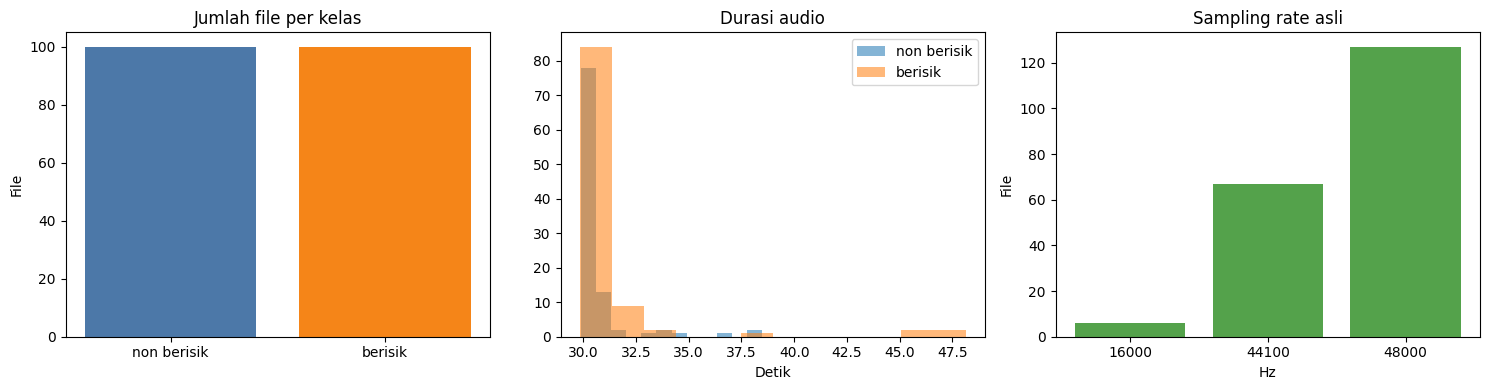

Durasi (detik):


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
berisik,100.0,31.249,3.413,29.845,30.0,30.187,30.903,48.135
non berisik,100.0,30.667,1.474,29.909,30.0,30.219,30.536,38.464


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
class_counts = inventory["label"].value_counts().reindex(CLASSES, fill_value=0)
axes[0].bar(class_counts.index, class_counts.values, color=["#4C78A8", "#F58518"])
axes[0].set_title("Jumlah file per kelas")
axes[0].set_ylabel("File")

for label in CLASSES:
    values = inventory.loc[inventory.label == label, "duration_seconds"].dropna()
    axes[1].hist(values, bins=12, alpha=.55, label=label)
axes[1].set_title("Durasi audio")
axes[1].set_xlabel("Detik")
axes[1].legend()

rate_counts = inventory["sample_rate"].value_counts().sort_index()
axes[2].bar(rate_counts.index.astype(str), rate_counts.values, color="#54A24B")
axes[2].set_title("Sampling rate asli")
axes[2].set_xlabel("Hz")
axes[2].set_ylabel("File")
plt.tight_layout()
plt.show()

print("Durasi (detik):")
display(inventory.groupby("label")["duration_seconds"].describe().round(3))

C:\Users\ARIEL\AppData\Local\Temp\ipykernel_11336\3772493245.py:20: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


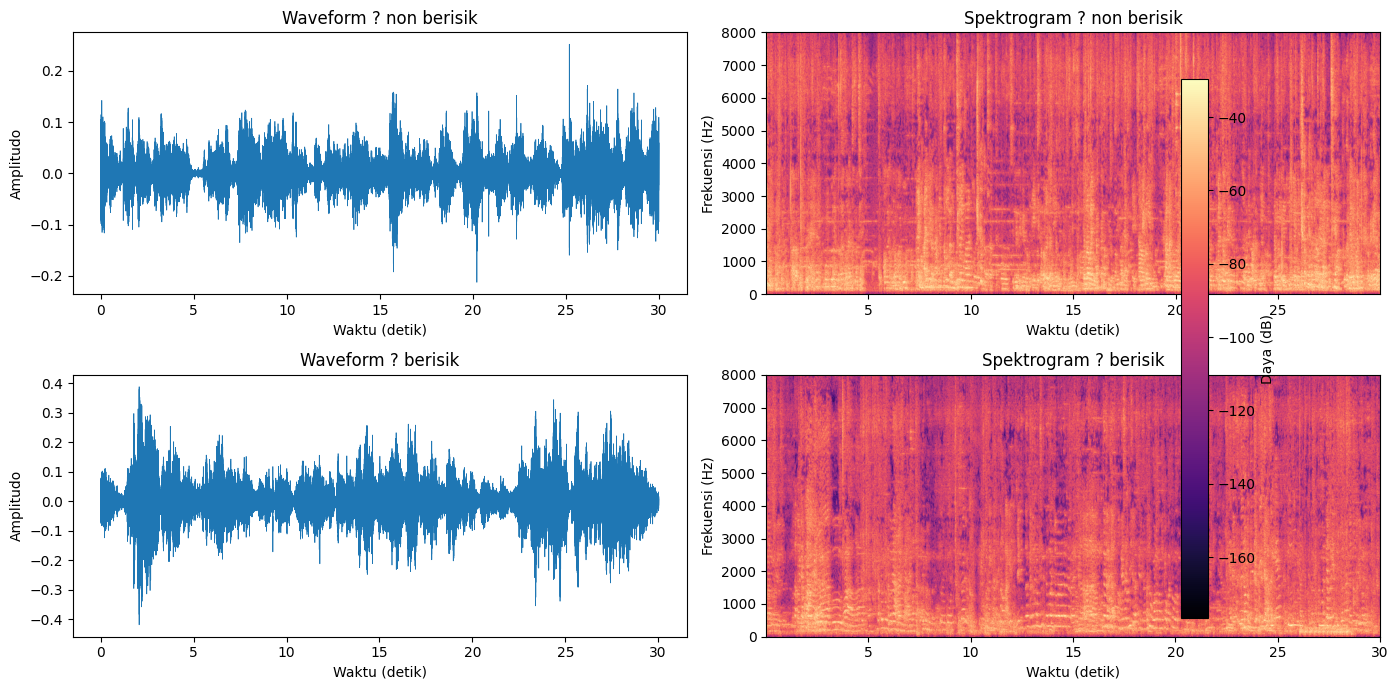

In [4]:
# Contoh waveform dan spektrogram per kelas setelah preprocessing mono 16 kHz.
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for row_index, label in enumerate(CLASSES):
    chosen = inventory.loc[(inventory.label == label) & inventory.valid].sort_values("record_id").iloc[0]
    waveform, _ = pipeline.load_mono_16k(ROOT / chosen.record_id)
    time_axis = np.arange(len(waveform)) / pipeline.SAMPLE_RATE
    axes[row_index, 0].plot(time_axis, waveform, linewidth=.5)
    axes[row_index, 0].set_title(f"Waveform ? {label}")
    axes[row_index, 0].set_xlabel("Waktu (detik)")
    axes[row_index, 0].set_ylabel("Amplitudo")
    _, _, _, image = axes[row_index, 1].specgram(
        waveform, NFFT=pipeline.FFT_SIZE, Fs=pipeline.SAMPLE_RATE,
        noverlap=pipeline.FFT_SIZE-pipeline.FFT_HOP_SIZE, cmap="magma"
    )
    axes[row_index, 1].set_ylim(0, 8000)
    axes[row_index, 1].set_title(f"Spektrogram ? {label}")
    axes[row_index, 1].set_xlabel("Waktu (detik)")
    axes[row_index, 1].set_ylabel("Frekuensi (Hz)")
fig.colorbar(image, ax=axes[:, 1].tolist(), label="Daya (dB)")
plt.tight_layout()
plt.show()

In [5]:
# Cari duplikasi byte-identical dan label yang bertentangan tanpa mengubah label.
valid_inventory = inventory.loc[inventory.valid.astype(bool)]
duplicate_groups = (valid_inventory.groupby("file_sha256", sort=False)
                    .filter(lambda group: len(group) > 1)
                    .sort_values(["file_sha256", "record_id"]))
if duplicate_groups.empty:
    print("Tidak ditemukan duplikasi byte-identical.")
else:
    display(duplicate_groups[["record_id", "label", "source_group", "file_sha256"]])
    per_hash = duplicate_groups.groupby("file_sha256").agg(
        file_count=("record_id", "size"),
        class_count=("label", "nunique"),
        files=("record_id", lambda values: " | ".join(values)),
        labels=("label", lambda values: ", ".join(sorted(set(values)))),
    ).reset_index()
    print("Klaster hash duplikat:", len(per_hash))
    print("Salinan ekstra:", int((per_hash.file_count - 1).sum()))
    print("Hash dengan label bertentangan:", int((per_hash.class_count > 1).sum()))
    display(per_hash.loc[per_hash.class_count > 1])

print("Catatan: hash hanya mendeteksi file byte-identical; kemiripan audio yang dikompresi ulang tidak dinyatakan sebagai duplikat otomatis.")

,record_id,label,source_group,file_sha256
101,non-berisik/24-003 sunyi 3.mp3,non berisik,24-003,0cf93360ec6819883636ac1de7bc5c76dc7fb4ea9aa469...
132,non-berisik/24-079 non-berisik 1.mp3,non berisik,24-079,0cf93360ec6819883636ac1de7bc5c76dc7fb4ea9aa469...
50,berisik/24-115 sampel berisik 3.mp3,berisik,24-115,1854df9da6f6c2287b97ddd860496165b7aa9264df1fe7...
88,berisik/24-190 berisik 3.mp3,berisik,24-190,1854df9da6f6c2287b97ddd860496165b7aa9264df1fe7...
129,non-berisik/24-078_NonBerisik 1.mp3,non berisik,24-078,26cf6fe08eb8c482e25cf4262dc5c6108d823db2c740d4...
130,non-berisik/24-078_NonBerisik 2.mp3,non berisik,24-078,26cf6fe08eb8c482e25cf4262dc5c6108d823db2c740d4...
131,non-berisik/24-078_NonBerisik 3.mp3,non berisik,24-078,26cf6fe08eb8c482e25cf4262dc5c6108d823db2c740d4...
0,berisik/24-003 berisik (1).mp3,berisik,24-003,42a343c79bf6060e5eb2b762bf1fb61ff3f8d553574118...
22,berisik/24-053 berisik 3.mp3,berisik,24-053,42a343c79bf6060e5eb2b762bf1fb61ff3f8d553574118...
26,berisik/24-071 berisik 2.mp3,berisik,24-071,4b947979d7fe6e493d0a804ff0a59d5fda13407f2cb66b...


Klaster hash duplikat: 16
Salinan ekstra: 21
Hash dengan label bertentangan: 1


,file_sha256,file_count,class_count,files,labels
13,c963e6beecaa3b2cff4db82b8f86aafa4e50ab33ea7065...,2,2,berisik/24-034 berisik 1.mp3 | non-berisik/24-...,"berisik, non berisik"


Catatan: hash hanya mendeteksi file byte-identical; kemiripan audio yang dikompresi ulang tidak dinyatakan sebagai duplikat otomatis.


## 3. Data Preparation

Audio diubah menjadi mono dan di-resample ke 16 kHz untuk ekstraksi yang seragam. Nilai non-finite diganti nol dengan pencatatan; amplitudo tidak dinormalisasi per file. Rekaman pendek dipad dengan nol hingga window 30 detik. Rekaman lebih panjang dipotong menjadi window 30 detik dengan hop 15 detik, dan tail disertakan jika sisa durasinya minimal 7,5 detik. Strategi window sama untuk semua fitur dan inferensi.

File senyap atau indikasi clipping tetap dicatat, bukan dibuang diam-diam. File yang tidak dapat dibaca diberi status invalid dan error-nya disimpan di inventaris.

## 4. Feature Engineering ? tepat 28 fitur

| Kelompok | Kolom | Cara membentuk |
|---|---|---|
| RMS (5) | `rms_overall`, `rms_frame_mean`, `rms_frame_std`, `rms_frame_min`, `rms_frame_max` | RMS waveform penuh; lalu mean, standar deviasi, minimum, dan maksimum RMS dari frame 1 detik dengan hop 0,5 detik |
| Spectral Centroid (5) | `centroid_mean`, `centroid_std`, `centroid_median`, `centroid_p10`, `centroid_p90` | Lima ringkasan centroid tiap frame 1024 sampel/hop 512 |
| ZCR (5) | `zcr_mean`, `zcr_std`, `zcr_median`, `zcr_p10`, `zcr_p90` | Lima ringkasan rasio lintas nol tiap frame 1024 sampel/hop 512 |
| MFCC (13) | `mfcc_00` sampai `mfcc_12` | Koefisien C0?C12 dari 64 mel band, log daya, DCT-II ortonormal; satu mean antarframe per koefisien |

RMS mengikuti rumus `sqrt(mean(x?))`; ia menunjukkan energi amplitudo relatif, bukan dB SPL terkalibrasi. Centroid merangkum letak pusat spektrum, ZCR merangkum pergantian tanda sinyal, dan MFCC meringkas bentuk spektral pada skala mel. Nilai temporal diringkas sesuai tabel sehingga setiap rekaman menghasilkan 28 angka.

In [6]:
# Ekstrak fitur dari semua file yang dapat dibaca. Progress dicetak tiap 10 audio.
inventory, feature_table = pipeline.extract_feature_table(inventory, progress=True)
print("Audio valid setelah ekstraksi:", int(inventory.valid.astype(bool).sum()))
print("Audio gagal dibaca saat ekstraksi:", int((~inventory.valid.astype(bool)).sum()))
print("Bentuk tabel fitur:", feature_table.shape)
print("Jumlah fitur numerik:", len(FEATURE_COLUMNS))

# Perbarui artefak inventaris dengan status clipping/senyap hasil preprocessing.
inventory_csv_path = save_csv_safely(
    pipeline.inventory_csv_view(inventory), ARTIFACTS / "inventaris_audio.csv"
)
print("Inventaris tersimpan:", inventory_csv_path.relative_to(ROOT))
if (~inventory.valid.astype(bool)).any():
    display(inventory.loc[~inventory.valid.astype(bool), ["record_id", "error"]])

Ekstraksi fitur: 10/200


Ekstraksi fitur: 20/200


Ekstraksi fitur: 30/200


Ekstraksi fitur: 40/200


Ekstraksi fitur: 50/200


...

Ekstraksi fitur: 160/200


Ekstraksi fitur: 170/200


Ekstraksi fitur: 180/200


Ekstraksi fitur: 190/200


Ekstraksi fitur: 200/200
Audio valid setelah ekstraksi: 200
Audio gagal dibaca saat ekstraksi: 0
Bentuk tabel fitur: (200, 33)
Jumlah fitur numerik: 28
Inventaris tersimpan: procesingdata\artifacts\inventaris_audio.csv


Kolom fitur, urutan final:
01. rms_overall
02. rms_frame_mean
03. rms_frame_std
04. rms_frame_min
05. rms_frame_max
06. centroid_mean
07. centroid_std
08. centroid_median
09. centroid_p10
10. centroid_p90
11. zcr_mean
12. zcr_std
13. zcr_median
14. zcr_p10
15. zcr_p90
16. mfcc_00
17. mfcc_01
18. mfcc_02
19. mfcc_03
20. mfcc_04
21. mfcc_05
22. mfcc_06
23. mfcc_07
24. mfcc_08
25. mfcc_09
26. mfcc_10
27. mfcc_11
28. mfcc_12
NaN fitur: 0
Nilai non-finite fitur: 0


,record_id,label,rms_overall,rms_frame_mean,rms_frame_std,rms_frame_min,rms_frame_max,centroid_mean,centroid_std,centroid_median,...,mfcc_03,mfcc_04,mfcc_05,mfcc_06,mfcc_07,mfcc_08,mfcc_09,mfcc_10,mfcc_11,mfcc_12
0,berisik/24-003 berisik (1).mp3,berisik,0.048302,0.045113,0.018143,0.017783,0.092584,1671.473238,460.055378,1615.325495,...,0.381723,-1.957729,-13.065898,-4.653938,-1.093690,-6.421377,1.380951,-1.812060,-3.131438,-11.012369
1,berisik/24-003 berisik (2).mp3,berisik,0.092774,0.085542,0.037008,0.012523,0.168175,2083.586446,717.520859,1972.580103,...,25.256243,-40.195947,5.093364,-16.111885,-7.912129,-1.746543,-1.014697,-2.670641,-1.602823,-9.960805
2,berisik/24-003 berisik (3).mp3,berisik,0.068651,0.063067,0.028329,0.003330,0.138661,2872.730583,848.544800,2828.576826,...,33.111418,-37.848062,26.010663,-17.363084,-0.143693,4.403589,-4.641792,3.386584,-6.032971,-7.650825
3,berisik/24-006 berisik 1.mp3,berisik,0.043592,0.042660,0.010308,0.022785,0.067346,1367.082335,307.106622,1295.409988,...,9.569976,-12.202528,-8.476655,-8.202807,-5.216291,-1.805551,-2.078974,-3.790268,-7.195994,-1.972713
4,berisik/24-006 berisik 2.mp3,berisik,0.034343,0.033465,0.009354,0.008103,0.053868,1310.867090,328.314104,1250.984194,...,6.916899,-10.131300,-4.953135,-6.322374,-3.708239,-3.216781,-3.837065,-5.598084,-7.612636,-2.145113


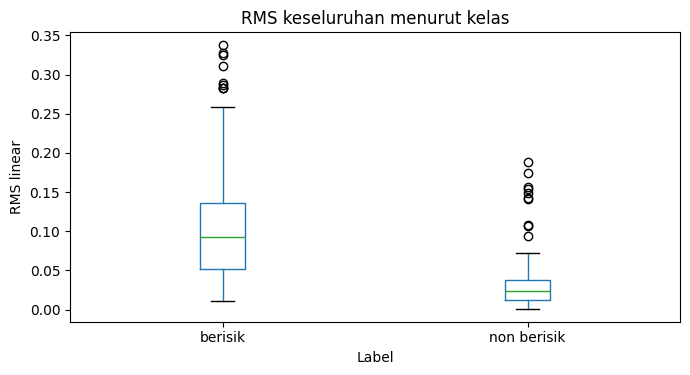

Median RMS per kelas:


label
non berisik    0.023347
berisik        0.092774
Name: rms_overall, dtype: float64

RMS sendiri belum menjadi bukti bahwa semua jenis kebisingan terpisah; variasi gain/perangkat perlu diperhatikan.
Audio senyap: 0
Audio dengan clipping proxy > 0: 37


In [7]:
print("Kolom fitur, urutan final:")
for number, name in enumerate(FEATURE_COLUMNS, start=1):
    print(f"{number:02d}. {name}")
assert len(FEATURE_COLUMNS) == 28
assert feature_table[FEATURE_COLUMNS].shape[1] == 28
assert np.isfinite(feature_table[FEATURE_COLUMNS].to_numpy(dtype=float)).all()
assert feature_table["record_id"].is_unique
print("NaN fitur:", int(feature_table[FEATURE_COLUMNS].isna().sum().sum()))
print("Nilai non-finite fitur:", int((~np.isfinite(feature_table[FEATURE_COLUMNS].to_numpy(dtype=float))).sum()))
display(feature_table[["record_id", "label", *FEATURE_COLUMNS]].head())

fig, ax = plt.subplots(figsize=(7, 4))
feature_table.boxplot(column="rms_overall", by="label", ax=ax, grid=False)
ax.set_title("RMS keseluruhan menurut kelas")
ax.set_xlabel("Label")
ax.set_ylabel("RMS linear")
fig.suptitle("")
plt.tight_layout()
plt.show()
print("Median RMS per kelas:")
display(feature_table.groupby("label").rms_overall.median().reindex(CLASSES))
print("RMS sendiri belum menjadi bukti bahwa semua jenis kebisingan terpisah; variasi gain/perangkat perlu diperhatikan.")
print("Audio senyap:", int(inventory.silent.fillna(False).astype(bool).sum()))
print("Audio dengan clipping proxy > 0:", int((inventory.clipped_fraction.fillna(0) > 0).sum()))

### Pemeriksaan duplikasi, grup, dan split sebelum modeling

Semua file fitur valid dimasukkan ke salah satu split, dan tabel pembagian harus mencakup seluruh jumlah file. Rekaman dengan `source_group` sama selalu berada pada sisi split yang sama. Audio byte-identical lintas nama/grup juga disatukan ke grup kebocoran yang sama, termasuk audio yang memiliki label berbeda.

Untuk modeling, salinan byte-identical berlabel konsisten hanya dihitung sekali agar tidak memberi bobot berlebih. Audio identik dengan label berbeda tetap masuk ke split dan CSV fitur, tetapi dikeluarkan dari fitting/evaluasi dengan alasan yang terlihat; label aslinya tidak diubah. Karena itu, jumlah file dalam tabel split mentah berjumlah 200, sedangkan jumlah sampel unik yang dipakai model akan lebih sedikit.

Split memakai `StratifiedGroupKFold` tujuh fold dengan beberapa seed tetap. Pasangan validation/test dipilih berdasarkan kedekatan jumlah file dan keseimbangan label terhadap target 70/15/15; akurasi atau metrik model tidak dipakai memilih split. Pencarian parameter memakai grouped 5-fold CV pada data train saja.


In [8]:
enriched_features, model_table, conflict_hashes = pipeline.duplicate_audit(feature_table)
# Pembagian dilakukan atas setiap file fitur, sehingga jumlah split mentah mencakup semua file.
raw_train, raw_validation, raw_test, selected_folds, split_candidates = (
    pipeline.grouped_train_validation_test_split(enriched_features)
)
raw_subsets = {
    "train": raw_train,
    "validation": raw_validation,
    "test": raw_test,
}
assignment_frames = []
for split_name, subset in raw_subsets.items():
    assignment_frames.append(subset[["record_id"]].assign(split=split_name))
assignments = pd.concat(assignment_frames, ignore_index=True)
assert assignments["record_id"].is_unique
assert len(assignments) == len(feature_table), "Setiap audio valid harus mendapat tepat satu split."
enriched_features = enriched_features.drop(columns=["split"], errors="ignore").merge(
    assignments, on="record_id", how="left", validate="one_to_one"
)
assert enriched_features["split"].notna().all()
assert len(enriched_features) == len(feature_table)

# Filter representatif hash unik untuk modeling, tetapi semua baris tetap tercatat di split.
group_to_split = enriched_features.groupby("leakage_group")["split"].nunique()
assert (group_to_split == 1).all(), "Satu grup sumber terpecah ke split berbeda."
group_to_split = enriched_features.groupby("leakage_group")["split"].first()
model_table["split"] = model_table["leakage_group"].map(group_to_split)
assert model_table["split"].notna().all()
train_data = model_table.loc[model_table.split == "train"].copy().reset_index(drop=True)
validation_data = model_table.loc[model_table.split == "validation"].copy().reset_index(drop=True)
test_data = model_table.loc[model_table.split == "test"].copy().reset_index(drop=True)

representative_ids = set(model_table.record_id)
enriched_features["is_model_representative"] = enriched_features.record_id.isin(representative_ids)
copy_mask = (~enriched_features.is_model_representative) & (~enriched_features.file_sha256.isin(conflict_hashes))
enriched_features.loc[copy_mask, "model_status"] = "duplicate_copy_same_audio"

# File dataset hanya memuat tiga kolom identitas diikuti 28 fitur numerik.
feature_export_columns = ["record_id", "file_name", "label", *FEATURE_COLUMNS]
feature_export = enriched_features[feature_export_columns].copy()
assert len(feature_export) == len(feature_table)
assert feature_export.columns.tolist() == ["record_id", "file_name", "label", *FEATURE_COLUMNS]
assert len(FEATURE_COLUMNS) == 28
model_subsets = {"train": train_data, "validation": validation_data, "test": test_data}
for left_name, left in model_subsets.items():
    for right_name, right in model_subsets.items():
        if left_name >= right_name:
            continue
        assert set(left.leakage_group).isdisjoint(set(right.leakage_group))
        assert set(left.file_sha256).isdisjoint(set(right.file_sha256))
feature_csv_path = save_csv_safely(feature_export, ARTIFACTS / "dataset_fitur_audio.csv")

# Manifest terpisah mencatat seluruh file dan statusnya dalam split.
split_manifest = enriched_features[[
    "record_id", "label", "source_group", "leakage_group", "file_sha256",
    "model_status", "is_model_representative", "split"
]].copy()
split_csv_path = save_csv_safely(split_manifest, ARTIFACTS / "pembagian_data.csv")
print("CSV fitur:", feature_csv_path.relative_to(ROOT))
print("Kolom CSV fitur:", len(feature_export.columns), "(3 identitas + 28 fitur)")
print("Baris fitur:", len(feature_export), "| jumlah split mentah:", sum(len(x) for x in raw_subsets.values()))
print("Data modeling unik setelah deduplikasi/konflik:", len(model_table))
print("Hash konflik label dikecualikan dari modeling:", len(conflict_hashes))
print("Fold/seed terpilih (validation/test):", selected_folds["validation_fold"], "/", selected_folds["test_fold"], "/", selected_folds["seed"])
for name, subset in raw_subsets.items():
    print(f"File mentah {name}: {len(subset)} ({len(subset)/len(feature_table):.1%})")
raw_split_table = pd.crosstab(enriched_features["split"], enriched_features["label"]).reindex(
    index=["train", "validation", "test"], columns=CLASSES, fill_value=0
)
display(raw_split_table)
assert int(raw_split_table.to_numpy().sum()) == len(feature_table)
print("Jumlah file mentah di semua split:", int(raw_split_table.to_numpy().sum()))
print("Jumlah audio unik yang masuk modeling per split:")
display(pd.crosstab(model_table["split"], model_table["label"]).reindex(
    index=["train", "validation", "test"], columns=CLASSES, fill_value=0))
print("Manifest split:", split_csv_path.relative_to(ROOT))
display(feature_export.head())


CSV fitur: procesingdata\artifacts\dataset_fitur_audio.csv
Kolom CSV fitur: 31 (3 identitas + 28 fitur)
Baris fitur: 200 | jumlah split mentah: 200
Data modeling unik setelah deduplikasi/konflik: 178
Hash konflik label dikecualikan dari modeling: 1
Fold/seed terpilih (validation/test): 1 / 4 / 45
File mentah train: 140 (70.0%)
File mentah validation: 30 (15.0%)
File mentah test: 30 (15.0%)


label,non berisik,berisik
split,,
train,70,70
validation,15,15
test,15,15


Jumlah file mentah di semua split: 200
Jumlah audio unik yang masuk modeling per split:


label,non berisik,berisik
split,,
train,60,60
validation,15,15
test,14,14


Manifest split: procesingdata\artifacts\pembagian_data.csv


,record_id,file_name,label,rms_overall,rms_frame_mean,rms_frame_std,rms_frame_min,rms_frame_max,centroid_mean,centroid_std,...,mfcc_03,mfcc_04,mfcc_05,mfcc_06,mfcc_07,mfcc_08,mfcc_09,mfcc_10,mfcc_11,mfcc_12
0,berisik/24-003 berisik (1).mp3,24-003 berisik (1).mp3,berisik,0.048302,0.045113,0.018143,0.017783,0.092584,1671.473238,460.055378,...,0.381723,-1.957729,-13.065898,-4.653938,-1.093690,-6.421377,1.380951,-1.812060,-3.131438,-11.012369
1,berisik/24-003 berisik (2).mp3,24-003 berisik (2).mp3,berisik,0.092774,0.085542,0.037008,0.012523,0.168175,2083.586446,717.520859,...,25.256243,-40.195947,5.093364,-16.111885,-7.912129,-1.746543,-1.014697,-2.670641,-1.602823,-9.960805
2,berisik/24-003 berisik (3).mp3,24-003 berisik (3).mp3,berisik,0.068651,0.063067,0.028329,0.003330,0.138661,2872.730583,848.544800,...,33.111418,-37.848062,26.010663,-17.363084,-0.143693,4.403589,-4.641792,3.386584,-6.032971,-7.650825
3,berisik/24-006 berisik 1.mp3,24-006 berisik 1.mp3,berisik,0.043592,0.042660,0.010308,0.022785,0.067346,1367.082335,307.106622,...,9.569976,-12.202528,-8.476655,-8.202807,-5.216291,-1.805551,-2.078974,-3.790268,-7.195994,-1.972713
4,berisik/24-006 berisik 2.mp3,24-006 berisik 2.mp3,berisik,0.034343,0.033465,0.009354,0.008103,0.053868,1310.867090,328.314104,...,6.916899,-10.131300,-4.953135,-6.322374,-3.708239,-3.216781,-3.837065,-5.598084,-7.612636,-2.145113


## 5. Modeling ? SVM sebagai model utama

SVM RBF dipertahankan. `StandardScaler` berada di dalam `Pipeline`, sehingga setiap fold CV mempelajari scaling dari bagian training fold saja. Grid search mencoba `C` dan `gamma`, memakai F1 macro, dan hanya menerima data train beserta grupnya. Setelah konfigurasi dipilih dari CV, hasilnya dilaporkan pada validation; model final kemudian di-fit ulang pada gabungan train+validation. Test tidak digunakan untuk tuning atau pemilihan model. Karena kandidat modeling setelah deduplikasi seimbang, `class_weight` tidak diaktifkan.


In [9]:
search, cv_results = pipeline.tune_svm(train_data)
cv_results_path = save_csv_safely(
    cv_results[["rank_test_score", "mean_test_score", "std_test_score", "params"]],
    ARTIFACTS / "hasil_cross_validation.csv"
)
print("Best params (training CV):", search.best_params_)
print("Best grouped CV F1 macro:", round(float(search.best_score_), 4))
print("CV hasil tersimpan:", cv_results_path.relative_to(ROOT))
display(cv_results[["rank_test_score", "mean_test_score", "std_test_score", "params"]].head(10))

Best params (training CV): {'svc__C': 1, 'svc__gamma': 'scale'}
Best grouped CV F1 macro: 0.7982
CV hasil tersimpan: procesingdata\artifacts\hasil_cross_validation.csv


,rank_test_score,mean_test_score,std_test_score,params
4,1,0.798172,0.100484,"{'svc__C': 1, 'svc__gamma': 'scale'}"
5,2,0.796328,0.104023,"{'svc__C': 1, 'svc__gamma': 0.01}"
8,3,0.790840,0.121597,"{'svc__C': 10, 'svc__gamma': 'scale'}"
6,4,0.780253,0.141345,"{'svc__C': 1, 'svc__gamma': 0.1}"
9,5,0.759585,0.103867,"{'svc__C': 10, 'svc__gamma': 0.01}"
0,6,0.748188,0.149105,"{'svc__C': 0.1, 'svc__gamma': 'scale'}"
10,7,0.718782,0.089966,"{'svc__C': 10, 'svc__gamma': 0.1}"
1,8,0.691863,0.193225,"{'svc__C': 0.1, 'svc__gamma': 0.01}"
12,9,0.687341,0.113850,"{'svc__C': 100, 'svc__gamma': 'scale'}"
14,10,0.686153,0.079711,"{'svc__C': 100, 'svc__gamma': 0.1}"


## 6. Evaluation

Pertama, konfigurasi SVM yang dipilih melalui CV train dievaluasi pada validation untuk melaporkan performa pengembangan. Sesudah itu pipeline yang sama di-fit ulang pada gabungan train dan validation, lalu dievaluasi satu kali pada test. Urutan confusion matrix adalah baris aktual dan kolom prediksi: `non berisik`, lalu `berisik`. Test adalah holdout internal berbasis grup, bukan evaluasi eksternal baru. Karena riwayat test lama pernah dilihat, tafsirkan hasil dengan caveat tersebut.


Metrik validation (model hasil CV train):


,precision,recall,f1-score,support
non berisik,0.6667,0.6667,0.6667,15.0000
berisik,0.6667,0.6667,0.6667,15.0000
accuracy,0.6667,0.6667,0.6667,0.6667
macro avg,0.6667,0.6667,0.6667,30.0000
weighted avg,0.6667,0.6667,0.6667,30.0000


Validation accuracy: 0.6667
Validation F1 macro: 0.6667


,precision,recall,f1-score,support
non berisik,0.5500,0.7857,0.6471,14.0000
berisik,0.6250,0.3571,0.4545,14.0000
accuracy,0.5714,0.5714,0.5714,0.5714
macro avg,0.5875,0.5714,0.5508,28.0000
weighted avg,0.5875,0.5714,0.5508,28.0000


Hasil test final:
Accuracy: 0.5714
Precision berisik: 0.6250
Recall berisik: 0.3571
F1 berisik: 0.4545
F1 macro: 0.5508
Confusion matrix (aktual x prediksi; non berisik, berisik ):
[[11  3]
 [ 9  5]]
Waktu prediksi: 0.000543 dtk total; 0.019 ms/file


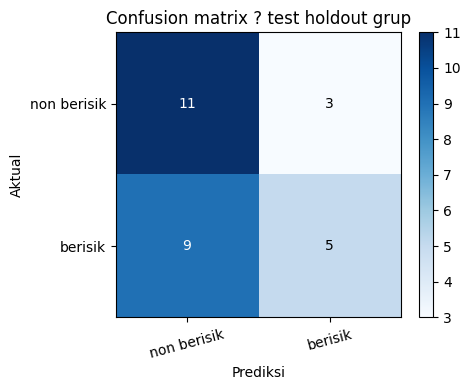

Kesalahan pada test:


,record_id,file_name,label,source_group,leakage_group,prediction,correct
0,berisik/24-007 berisikk 1.mp3,24-007 berisikk 1.mp3,berisik,24-007,24-007,non berisik,False
1,berisik/24-007 berisikkk 2.mp3,24-007 berisikkk 2.mp3,berisik,24-007,24-007,non berisik,False
2,berisik/24-007 berisikkk 3.mp3,24-007 berisikkk 3.mp3,berisik,24-007,24-007,non berisik,False
3,berisik/24-034 berisik 2.mp3,24-034 berisik 2.mp3,berisik,24-034,24-034,non berisik,False
4,berisik/24-034 berisik 3.mp3,24-034 berisik 3.mp3,berisik,24-034,24-034,non berisik,False
5,berisik/24-101_rame 1.mp3,24-101_rame 1.mp3,berisik,24-101,24-101,non berisik,False
6,berisik/24-101_rame 2.mp3,24-101_rame 2.mp3,berisik,24-101,24-101,non berisik,False
7,berisik/24-101_rame 3.mp3,24-101_rame 3.mp3,berisik,24-101,24-101,non berisik,False
12,berisik/24-202_berisik 2.MP3,24-202_berisik 2.MP3,berisik,24-202,24-202,non berisik,False
22,non-berisik/24-141 non-berisik (1).mp3,24-141 non-berisik (1).mp3,non berisik,24-141,24-141,berisik,False


In [10]:
validation_metrics, validation_predictions = pipeline.evaluate_svm(
    search.best_estimator_, validation_data, split_name="validation"
)
print("Metrik validation (model hasil CV train):")
display(pd.DataFrame(validation_metrics["classification_report"]).T.round(4))
print("Validation accuracy:", f"{validation_metrics['accuracy']:.4f}")
print("Validation F1 macro:", f"{validation_metrics['f1_macro']:.4f}")

# Setelah hasil validation dicatat, fit ulang pipeline terpilih pada seluruh data pengembangan.
from sklearn.base import clone
development_data = pd.concat([train_data, validation_data], ignore_index=True)
final_model = clone(search.best_estimator_)
final_model.fit(
    development_data[FEATURE_COLUMNS].to_numpy(dtype=np.float32),
    development_data["label"].to_numpy(),
)
test_metrics, test_predictions = pipeline.evaluate_svm(
    final_model, test_data, split_name="test"
)
report_table = pd.DataFrame(test_metrics["classification_report"]).T
display(report_table.round(4))
print("Hasil test final:")
print("Accuracy:", f"{test_metrics['accuracy']:.4f}")
print("Precision berisik:", f"{test_metrics['precision_berisik']:.4f}")
print("Recall berisik:", f"{test_metrics['recall_berisik']:.4f}")
print("F1 berisik:", f"{test_metrics['f1_berisik']:.4f}")
print("F1 macro:", f"{test_metrics['f1_macro']:.4f}")
print("Confusion matrix (aktual x prediksi;", ", ".join(CLASSES), "):")
print(np.asarray(test_metrics["confusion_matrix"]))
print("Waktu prediksi:", f"{test_metrics['inference_seconds']:.6f} dtk total; "
      f"{test_metrics['inference_ms_per_record']:.3f} ms/file")

cm = np.asarray(test_metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(2), CLASSES, rotation=15)
ax.set_yticks(range(2), CLASSES)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
ax.set_title("Confusion matrix ? test holdout grup")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

print("Kesalahan pada test:")
errors = test_predictions.loc[~test_predictions.correct]
display(errors if not errors.empty else pd.DataFrame(columns=test_predictions.columns))


### Simpan model dan cek pemuatan ulang

Model tersimpan berisi pipeline scaler + SVM yang di-fit pada gabungan train dan validation serta daftar dan urutan 28 fitur. Metadata menyimpan parameter preprocessing, ukuran ketiga subset, parameter terpilih, versi dependensi, dan metrik validation/test aktual. Prediksi test dibandingkan sebelum dan sesudah `joblib.load`.


In [11]:
raw_class_counts = {
    name: subset["label"].value_counts().reindex(CLASSES, fill_value=0).astype(int).to_dict()
    for name, subset in raw_subsets.items()
}
split_info = {
    "train_count": len(train_data),
    "validation_count": len(validation_data),
    "test_count": len(test_data),
    "train_groups": train_data.leakage_group.nunique(),
    "validation_groups": validation_data.leakage_group.nunique(),
    "test_groups": test_data.leakage_group.nunique(),
    "train_raw_file_count": len(raw_train),
    "validation_raw_file_count": len(raw_validation),
    "test_raw_file_count": len(raw_test),
    "raw_class_counts": raw_class_counts,
}
model_path = ARTIFACTS / "svm_pipeline.joblib"
metadata_path = ARTIFACTS / "metadata_svm.json"
bundle, metadata = pipeline.save_model_and_metadata(
    final_model, validation_metrics, test_metrics, split_info, conflict_hashes,
    selected_folds, search.best_score_, search.best_params_,
    model_path, metadata_path,
)

# Simpan kedua hasil evaluasi aktual dan prediksi test untuk ditelusuri.
(ARTIFACTS / "hasil_evaluasi.json").write_text(
    json.dumps({"validation": validation_metrics, "test": test_metrics},
               ensure_ascii=False, indent=2, default=str), encoding="utf-8"
)
predictions_path = save_csv_safely(test_predictions, ARTIFACTS / "prediksi_test.csv")
print("Model:", model_path.relative_to(ROOT))
print("Metadata:", metadata_path.relative_to(ROOT))
print("Prediksi test:", predictions_path.relative_to(ROOT))
print("Jumlah fitur dalam bundle:", len(bundle["feature_columns"]))


Model: procesingdata\artifacts\svm_pipeline.joblib
Metadata: procesingdata\artifacts\metadata_svm.json
Prediksi test: procesingdata\artifacts\prediksi_test.csv
Jumlah fitur dalam bundle: 28


In [12]:
reloaded = joblib.load(model_path)
X_holdout = test_data[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
pred_before = final_model.predict(X_holdout)
pred_after = reloaded["pipeline"].predict(X_holdout)
assert np.array_equal(pred_before, pred_after), "Prediksi berubah setelah model dimuat ulang."
print("Konsistensi prediksi seluruh test setelah reload:", bool(np.array_equal(pred_before, pred_after)))

# Cek fungsi inferensi audio mentah dengan resep 28 fitur yang sama.
example = test_data.iloc[0]
inference = pipeline.infer_audio_file(ROOT / example.record_id, reloaded["pipeline"])
expected = str(final_model.predict(
    example[FEATURE_COLUMNS].to_numpy(dtype=np.float32).reshape(1, -1)
)[0])
assert inference["feature_count"] == 28
assert inference["prediction"] == expected
print("Contoh inferensi file test:", inference)


Konsistensi prediksi seluruh test setelah reload: True


Contoh inferensi file test: {'record_id': '24-007 berisikk 1.mp3', 'prediction': 'non berisik', 'rms_overall': 0.048014702451127426, 'quality': {'original_sample_rate': 48000, 'original_channels': 1, 'clipped_fraction': 0.0, 'silent': False}, 'feature_count': 28}


In [13]:
print("RINGKASAN CRISP-DM")
print(f"File ditemukan: {len(inventory)}; valid setelah pembacaan fitur: {int(inventory.valid.astype(bool).sum())}; gagal: {int((~inventory.valid.astype(bool)).sum())}")
print("Jumlah label mentah:", inventory.label.value_counts().reindex(CLASSES, fill_value=0).to_dict())
print("CSV fitur:", len(feature_export.columns), "kolom (record_id, file_name, label + 28 fitur)")
print("Fitur per rekaman:", len(FEATURE_COLUMNS), "(RMS 5 + centroid 5 + ZCR 5 + MFCC 13)")
print("Jumlah file mentah dalam split:", sum(len(x) for x in raw_subsets.values()), "dari", len(feature_table))
for name, subset in raw_subsets.items():
    model_subset = model_subsets[name]
    print(f"Split {name}: {len(subset)} file mentah; {len(model_subset)} audio unik dipakai modeling ({len(subset)/len(feature_table):.1%})")
print(f"Model SVM RBF; grouped CV F1 macro={search.best_score_:.4f}; parameter={search.best_params_}")
print(f"Validation accuracy={validation_metrics['accuracy']:.4f}, F1 macro={validation_metrics['f1_macro']:.4f}")
print(f"Test accuracy={test_metrics['accuracy']:.4f}, F1 macro={test_metrics['f1_macro']:.4f}, recall berisik={test_metrics['recall_berisik']:.4f}")
print("Model tersimpan:", model_path.relative_to(ROOT))
print("Evaluasi eksternal independen tetap memerlukan rekaman baru dari grup/sumber yang belum pernah dilihat.")


RINGKASAN CRISP-DM
File ditemukan: 200; valid setelah pembacaan fitur: 200; gagal: 0
Jumlah label mentah: {'non berisik': 100, 'berisik': 100}
CSV fitur: 31 kolom (record_id, file_name, label + 28 fitur)
Fitur per rekaman: 28 (RMS 5 + centroid 5 + ZCR 5 + MFCC 13)
Jumlah file mentah dalam split: 200 dari 200
Split train: 140 file mentah; 120 audio unik dipakai modeling (70.0%)
Split validation: 30 file mentah; 30 audio unik dipakai modeling (15.0%)
Split test: 30 file mentah; 28 audio unik dipakai modeling (15.0%)
Model SVM RBF; grouped CV F1 macro=0.7982; parameter={'svc__C': 1, 'svc__gamma': 'scale'}
Validation accuracy=0.6667, F1 macro=0.6667
Test accuracy=0.5714, F1 macro=0.5508, recall berisik=0.3571
Model tersimpan: procesingdata\artifacts\svm_pipeline.joblib
Evaluasi eksternal independen tetap memerlukan rekaman baru dari grup/sumber yang belum pernah dilihat.
